# Spektrální signatury ze Sentinelu-2: les, pole, voda a sníh (Brno a Jeseníky)

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_brno_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Spektrální signatury](https://openskylab.space/edu_viz_spectral_signatures.html) · [English version](spectral_signatures_brno_en.ipynb)

Vizuál ukazuje, jak chlorofyl, voda v listech, sušina a LAI mění spektrální křivku vegetace a proč NDVI v hustém porostu přestává růst. Tady to ověříš na skutečných pixelech Sentinelu-2 u Brněnské přehrady a na časové řadě jednoho pole během sezóny 2024.

**Cíl:** porovnat skutečné spektrální křivky povrchů, najít polohu červené hrany, ukázat nasycení NDVI na časové řadě pole a vysvětlit, proč stejný index z jiných pásem dává jiné číslo.

**Data:** Sentinel-2 L2A z katalogu Earth Search na AWS: scéna `S2B_33UXQ_20240814_0_L2A` (14. 8. 2024, okolí Brněnské přehrady), bezoblačné scény dlaždice 33UXQ z března až října 2024 pro časovou řadu a `S2B_33UXR_20240130_0_L2A` (Hrubý Jeseník kolem Pradědu se sněhem); třídy ESA WorldCover 2021. Stahuje se asi 30 MB, časová řada trvá 1 až 3 minuty.

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.windows import Window
from pyproj import Transformer

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E015_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Přečte rastr z cloudu a převzorkuje ho na mřížku grid = (transformace, crs, výška, šířka)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Odrazivost všech pásem Sentinelu-2 L2A ve čtverci kolem bodu (mřížka 10 m v UTM dlaždice)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # od základní linie zpracování 04.00 (2022) mají DN posun +1000; Earth Search ho u novějších položek už odečetl
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

## 2. Spektrální křivky skutečných povrchů

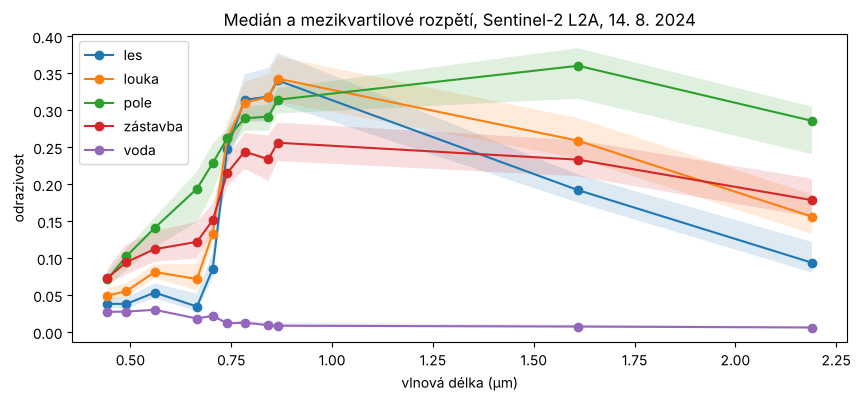

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UXQ_20240814_0_L2A", 16.52, 49.23, 2000)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
clear = np.isin(scl, [4, 5, 6])
classes = {10: "les", 30: "louka", 40: "pole", 50: "zástavba", 80: "voda"}
lam = np.array([wl[b] for b in BANDS])
fig, ax = plt.subplots(figsize=(10, 4))
curves = {}
for code, name in classes.items():
    m = clear & (wc == code)
    stack = np.array([refl[b][m] for b in BANDS])
    q25, q50, q75 = np.percentile(stack, [25, 50, 75], axis=1)
    curves[name] = q50
    ax.plot(lam, q50, "o-", label=name); ax.fill_between(lam, q25, q75, alpha=0.15)
ax.set(xlabel="vlnová délka (µm)", ylabel="odrazivost", title="Medián a mezikvartilové rozpětí, Sentinel-2 L2A, 14. 8. 2024")
ax.legend(); plt.show()

> **✏️ Úkol 1.** Popiš křivku lesa: proč je v modré a červené nízko, v zelené malé maximum a mezi 0,70 a 0,78 µm prudký nárůst? Proč má pole (v polovině srpna většinou strniště nebo podmítnutá půda) v červené víc a v NIR méně než les? Který povrch má v kterých pásmech největší rozptyl (šíři pásu kolem křivky) a proč?

*Tvoje odpověď:* 

## 3. Poloha červené hrany

Červená hrana je strmý nárůst odrazivosti mezi červenou a NIR. Její polohu (REP) odhadneme lineární interpolací z pásem B4, B5, B6 a B7 (Guyot a Baret 1988). Víc chlorofylu posouvá hranu k delším vlnovým délkám.

In [4]:
def rep(r4, r5, r6, r7):
    mid = (r4 + r7) / 2                                   # odrazivost v polovině hrany
    return 705 + 35 * (mid - r5) / (r6 - r5)             # nm (B5 = 705 nm, B6 = 740 nm)

REP = rep(refl["red"], refl["rededge1"], refl["rededge2"], refl["rededge3"])
for code, name in classes.items():
    m = clear & (wc == code)
    print(f"{name:9s}: REP medián {np.nanmedian(REP[m]):.1f} nm")

les      : REP medián 725.0 nm
louka    : REP medián 720.9 nm
pole     : REP medián 711.9 nm
zástavba : REP medián 722.4 nm
voda     : REP medián 726.4 nm


> **✏️ Úkol 2.** Který vegetační povrch má červenou hranu nejdál a proč? Má smysl počítat REP u vody nebo zástavby? Podívej se, jaké hodnoty vyjdou, a vysvětli, proč index bez vegetace nedává fyzikální smysl, i když vrátí číslo.

*Tvoje odpověď:* 

## 4. Nasycení NDVI během sezóny

Vezmeme jeden pixel pole severně od Bystrce a všechny bezoblačné snímky z roku 2024. Porovnáme NDVI = (NIR − R)/(NIR + R), NDRE = (NIR − RE1)/(NIR + RE1) a NDMI = (NIR − SWIR1)/(NIR + SWIR1).

scén v katalogu: 30


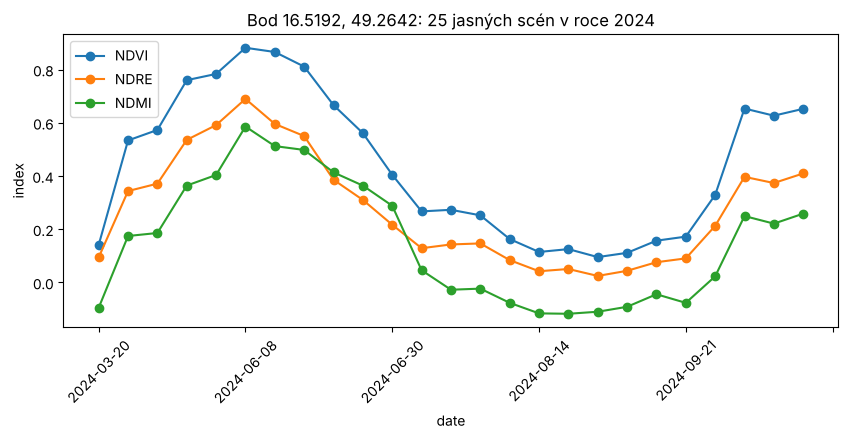

In [5]:
lon, lat = 16.5192, 49.2642          # ◀ parametr: bod (pole severně od Bystrce); zkus i les, např. 16.5087, 49.226
search = requests.post("https://earth-search.aws.element84.com/v1/search", json={
    "collections": ["sentinel-2-l2a"], "intersects": {"type": "Point", "coordinates": [lon, lat]},
    "datetime": "2024-03-01T00:00:00Z/2024-10-31T23:59:59Z", "limit": 100,
    "query": {"eo:cloud_cover": {"lt": 40}, "grid:code": {"eq": "MGRS-33UXQ"}}}, timeout=60).json()
print("scén v katalogu:", len(search["features"]))

def pixel(item, key, x, y):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + item["assets"][key]["href"]) as r:
            row, col = r.index(x, y)
            return float(r.read(1, window=Window(col - 1, row - 1, 3, 3)).mean() if key != "scl"
                         else r.read(1, window=Window(col, row, 1, 1))[0, 0])

rows = []
for it in sorted(search["features"], key=lambda f: f["properties"]["datetime"]):
    x, y = Transformer.from_crs(4326, 32633, always_xy=True).transform(lon, lat)
    if pixel(it, "scl", x, y) not in (4, 5):               # jen jasná vegetace nebo holá půda
        continue
    p = it["properties"]
    off = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    r = {k: (pixel(it, k, x, y) + off) / 10000 for k in ("red", "rededge1", "nir08", "nir", "swir16")}
    r["date"] = it["properties"]["datetime"][:10]
    rows.append(r)
ts = pd.DataFrame(rows).drop_duplicates("date").set_index("date")
ts["NDVI"] = (ts.nir - ts.red) / (ts.nir + ts.red)
ts["NDRE"] = (ts.nir - ts.rededge1) / (ts.nir + ts.rededge1)
ts["NDMI"] = (ts.nir08 - ts.swir16) / (ts.nir08 + ts.swir16)
ax = ts[["NDVI", "NDRE", "NDMI"]].plot(marker="o", figsize=(10, 3.8), rot=45)
ax.set(ylabel="index", title=f"Bod {lon}, {lat}: {len(ts)} jasných scén v roce 2024"); plt.show()

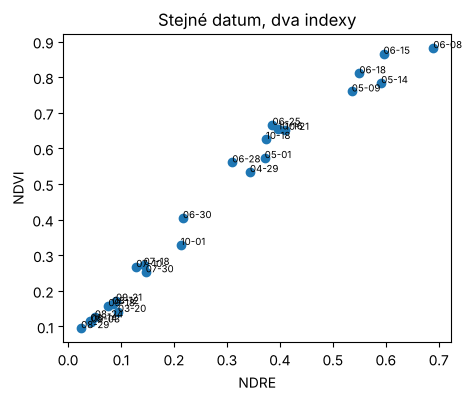

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(ts.NDRE, ts.NDVI)
for d, r in ts.iterrows(): ax.annotate(d[5:], (r.NDRE, r.NDVI), fontsize=7)
ax.set(xlabel="NDRE", ylabel="NDVI", title="Stejné datum, dva indexy"); plt.show()

> **✏️ Úkol 3.** Kdy pole dosáhlo maxima a kdy byla sklizeň? V jakém rozsahu NDVI se graf NDVI–NDRE ohýbá, tj. NDVI už skoro neroste, ale NDRE ano? Vysvětli nasycení: proč červená při vysokém LAI už nemůže klesnout níž, ale červená hrana se ještě posouvá?

*Tvoje odpověď:* 

> **✏️ Úkol 4.** Jak se během sezóny chová NDMI a proč klesá dřív nebo rychleji než NDVI, když porost dozrává? Změň bod na les (`16.5087, 49.226`) a porovnej: proč je u lesa řada mnohem plošší?

*Tvoje odpověď:* 

## 5. Voda a sníh

NDWI (zelená a NIR, McFeeters 1996) zvýrazní vodu, NDSI (zelená a SWIR 1,6 µm) sníh. Sníh je ve viditelném jasný, ale v SWIR pohlcuje; oblaka odrážejí v obou.

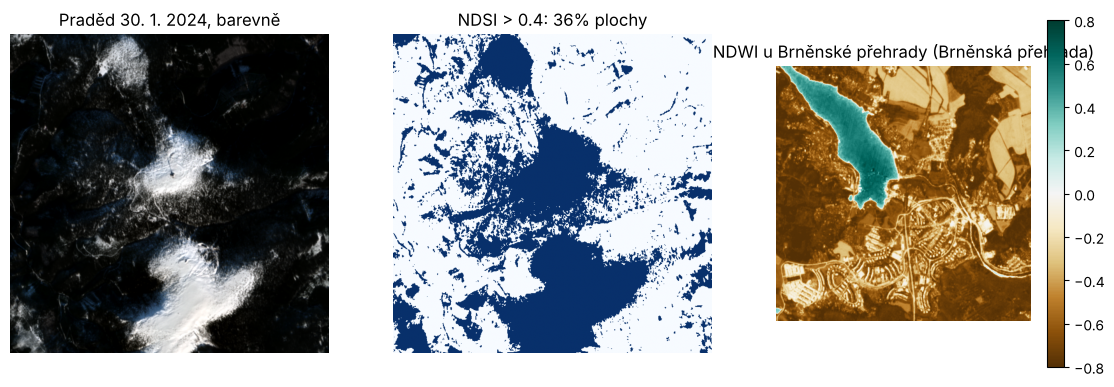

shoda s maskou sněhu SCL: 84.0% pixelů


In [7]:
snow, snow_scl, *_ = s2_window("S2B_33UXR_20240130_0_L2A", 17.23, 50.08, 3000)
ndsi = (snow["green"] - snow["swir16"]) / (snow["green"] + snow["swir16"])
ndwi = (refl["green"] - refl["nir"]) / (refl["green"] + refl["nir"])
thr = 0.4                               # ◀ parametr: práh NDSI pro sníh (MODIS používá 0,4)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
rgb = np.dstack([snow["red"], snow["green"], snow["blue"]]); ax[0].imshow(np.clip(rgb / 1.0, 0, 1)); ax[0].set_title("Praděd 30. 1. 2024, barevně")
ax[1].imshow(ndsi > thr, cmap="Blues"); ax[1].set_title(f"NDSI > {thr}: {np.mean(ndsi > thr):.0%} plochy")
im = ax[2].imshow(ndwi, cmap="BrBG", vmin=-0.8, vmax=0.8); ax[2].set_title("NDWI u Brněnské přehrady (Brněnská přehrada)"); fig.colorbar(im, ax=ax[2])
for a in ax: a.axis("off")
plt.show()
print(f"shoda s maskou sněhu SCL: {np.mean((ndsi > thr) == (snow_scl == 11)):.1%} pixelů")

> **✏️ Úkol 5.** Proč NDSI odliší sníh od oblaků, i když jsou ve viditelném oba bílé? Změň práh na 0,2 a 0,6: kde se maska mění nejvíc (zasněžený les, stíny, otevřené plochy)? Proč je voda (Brněnská přehrada) v NDWI kladná a vegetace záporná?

*Tvoje odpověď:* 

## 6. Stejný index, jiné číslo

NDVI lze ze Sentinelu-2 spočítat s širokým pásmem B8 (střed kolem 833 nm, šířka přes 100 nm, pixel 10 m) nebo s úzkým B8A (865 nm, šířka asi 21 nm, pixel 20 m). Dron s multispektrální kamerou nebo Landsat mají zase jiná pásma. Porovnáme obě varianty na stejných pixelech.

NDVI(B8A) − NDVI(B8) ve vegetaci: průměr +0.019, 5.–95. percentil -0.005 až +0.051


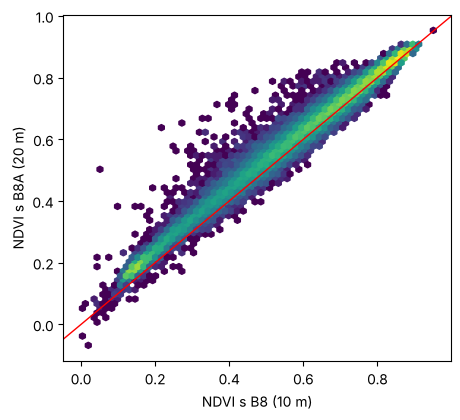

In [8]:
ndvi_b8 = (refl["nir"] - refl["red"]) / (refl["nir"] + refl["red"])
ndvi_b8a = (refl["nir08"] - refl["red"]) / (refl["nir08"] + refl["red"])
m = clear & np.isin(wc, [10, 30, 40])
d = (ndvi_b8a - ndvi_b8)[m]
print(f"NDVI(B8A) − NDVI(B8) ve vegetaci: průměr {d.mean():+.3f}, 5.–95. percentil {np.percentile(d, 5):+.3f} až {np.percentile(d, 95):+.3f}")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.hexbin(ndvi_b8[m], ndvi_b8a[m], gridsize=60, bins="log", cmap="viridis"); ax.axline((0, 0), slope=1, color="r", lw=1)
ax.set(xlabel="NDVI s B8 (10 m)", ylabel="NDVI s B8A (20 m)"); plt.show()

> **✏️ Úkol 6.** O kolik se obě NDVI liší a kterým směrem? Navrhni dvě příčiny (poloha a šířka pásma, rozlišení 10 vs. 20 m). Co z toho plyne, když chceš porovnat NDVI z dronu s NDVI ze Sentinelu-2 nebo staré a nové mapy NDVI?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Porovnej výsledky se spolužákem, který spustil notebook pro jiné místo: liší se červená hrana lesa, nasycení NDVI na poli nebo rozdíl NDVI(B8A) − NDVI(B8)? Čím to může být (plodina, druh lesa, datum snímku)?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); COG kopie v registru AWS Open Data (`sentinel-cogs`), katalog Earth Search (Element 84). Volné užití s uvedením zdroje podle [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice).
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Poloha červené hrany lineární interpolací: Guyot, G., Baret, F. (1988). Utilisation de la haute résolution spectrale pour suivre l'état des couverts végétaux. *Proc. 4th Int. Colloquium on Spectral Signatures of Objects in Remote Sensing*, ESA SP-287, 279–286.
- Nasycení NDVI a indexy s červenou hranou: Gitelson, A. A., Merzlyak, M. N. (1994). Spectral reflectance changes associated with autumn senescence of *Aesculus hippocastanum* L. and *Acer platanoides* L. leaves. *Journal of Plant Physiology* 143, 286–292. https://doi.org/10.1016/S0176-1617(11)81633-0
- NDWI: McFeeters, S. K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing* 17, 1425–1432. https://doi.org/10.1080/01431169608948714
- NDSI pro sníh: Hall, D. K., Riggs, G. A., Salomonson, V. V. (1995). Development of methods for mapping global snow cover using MODIS. *Remote Sensing of Environment* 54, 127–140. https://doi.org/10.1016/0034-4257(95)00137-P

### Jak citovat

OpenSkyLab (2026). Spektrální signatury ze Sentinelu-2: les, pole, voda a sníh (Brno a Jeseníky) [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_brno_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*